# 7. Chebyshev series and the FFT

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/07_chebyshev_series_and_fft.ipynb)

*Companion to Chapter 8 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

So far a function on $[-1, 1]$ has been stored as its **values** at the Chebyshev points. The
same polynomial can be stored as the **coefficients** of a Chebyshev series, and a fast
transform moves between the two descriptions. The coefficients answer questions the values
cannot: how smooth the function is, whether the grid is fine enough, and how short a formula
can replace it.

- Chebyshev series, Fourier cosine series and Laurent series are one thing in three variables
- values to coefficients and back with the discrete cosine transform
- reading smoothness and resolution off the coefficients
- evaluating a series anywhere, and differentiating it in $O(N\log N)$ operations

**Worked example:** replacing the Arrhenius rate constant by a short Chebyshev series accurate
to eight digits.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, fft

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

## 7.1 One function, three variables

The Chebyshev polynomial of degree $k$ is defined by

$$T_k(x) = \cos k\theta,\qquad x = \cos\theta .$$

That $\cos k\theta$ is a polynomial in $\cos\theta$ follows from
$\cos(k+1)\theta + \cos(k-1)\theta = 2\cos\theta\cos k\theta$, which is the recurrence
$T_{k+1} = 2xT_k - T_{k-1}$ with $T_0 = 1$ and $T_1 = x$. So $T_2 = 2x^2 - 1$,
$T_3 = 4x^3 - 3x$, and so on.

Now put $z = e^{i\theta}$, a point on the unit circle. Then $x = \cos\theta = \tfrac12(z + z^{-1})$
and $T_k = \tfrac12(z^k + z^{-k})$. A sum $\sum_k a_kT_k(x)$ can therefore be read in three ways.

| Variable | Where it lives | Term $k$ | The series is called | Natural grid |
| --- | --- | --- | --- | --- |
| $x$ | the interval $[-1, 1]$ | $T_k(x)$ | Chebyshev series | $x_j = \cos(j\pi/N)$ |
| $\theta$ | $[0, \pi]$, extended as an even periodic function | $\cos k\theta$ | Fourier cosine series | $\theta_j = j\pi/N$, equally spaced |
| $z$ | the unit circle | $\tfrac12(z^k + z^{-k})$ | Laurent series | $z_j = e^{ij\pi/N}$, roots of unity |

The change of variable $x = \cos\theta$ turns any function on $[-1, 1]$ into an even, periodic
function of $\theta$, **whether or not the original function was periodic**. The Chebyshev
points are the equally spaced angles seen through this change of variable. Everything learned
about Fourier methods in notebooks 2 and 3 (the FFT, the link between smoothness and decay of
coefficients, aliasing) therefore carries over to bounded intervals.

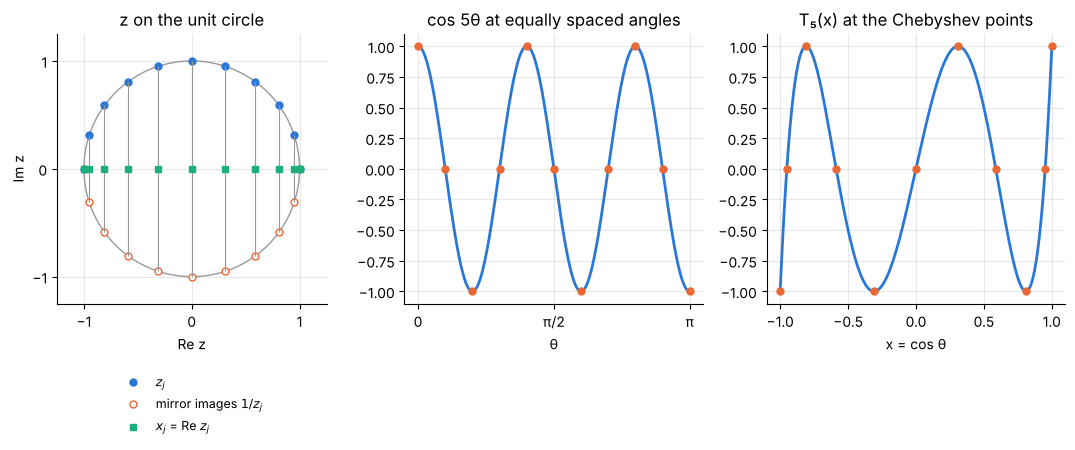

In [3]:
N, k = 10, 5
angles = np.pi * np.arange(N + 1) / N
fine_angle = np.linspace(0, np.pi, 400)

fig, axes = plt.subplots(1, 3, figsize=(11, 4.2))
circle = np.linspace(0, 2 * np.pi, 400)
axes[0].plot(np.cos(circle), np.sin(circle), color="0.6", lw=1)
axes[0].plot(np.cos(angles), np.sin(angles), "o", ms=5, label="$z_j$")
axes[0].plot(np.cos(angles[1:-1]), -np.sin(angles[1:-1]), "o", ms=5, mfc="white", label="mirror images $1/z_j$")
axes[0].vlines(np.cos(angles), -np.sin(angles), np.sin(angles), color="0.6", lw=0.8)
axes[0].plot(np.cos(angles), 0 * angles, "s", ms=4, label="$x_j$ = Re $z_j$")
axes[0].set(aspect="equal", xlabel="Re z", ylabel="Im z", title="z on the unit circle",
            xticks=[-1, 0, 1], yticks=[-1, 0, 1], xlim=(-1.25, 1.25), ylim=(-1.25, 1.25))
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), fontsize=9)
axes[1].plot(fine_angle, np.cos(k * fine_angle))
axes[1].plot(angles, np.cos(k * angles), "o", ms=5)
axes[1].set(xlabel="θ", title="cos 5θ at equally spaced angles", xticks=[0, np.pi / 2, np.pi], xticklabels=["0", "π/2", "π"])
axes[2].plot(np.cos(fine_angle), np.cos(k * fine_angle))
axes[2].plot(np.cos(angles), np.cos(k * angles), "o", ms=5)
axes[2].set(xlabel="x = cos θ", title="T₅(x) at the Chebyshev points")
fig.tight_layout()

The middle and right panels show the same eleven numbers. Plotted against $\theta$ they sample
a cosine wave at equal intervals. Plotted against $x = \cos\theta$ they sample the polynomial
$T_5$ at the Chebyshev points; the wave is compressed towards the ends, where $T_5$ oscillates
fastest. The left panel shows where the points come from: equally spaced points on the circle,
projected onto the real axis. Each interior Chebyshev point is the shadow of two points on the
circle, $z_j$ and $1/z_j$, which is why only cosines (even functions of $\theta$) appear.

In [4]:
x = np.cos(angles)
assert np.allclose(np.cos(3 * angles), 4 * x**3 - 3 * x, rtol=0, atol=1e-13)              # T_3 as a polynomial
z = np.exp(1j * angles)
assert np.allclose(np.cos(k * angles), ((z**k + z**-k) / 2).real, rtol=0, atol=1e-13)       # T_k as a Laurent polynomial

## 7.2 From values to coefficients

**Problem.** The polynomial $p$ of degree $N$ through the values $v_0, \dots, v_N$ at the
Chebyshev points can be written $p(x) = \sum_{k=0}^{N} a_kT_k(x)$. Find the $a_k$.

**By hand.** At the grid points $T_k(x_j) = \cos(jk\pi/N)$, so the conditions $p(x_j) = v_j$
read

$$v_j = \sum_{k=0}^{N} a_k\cos\frac{jk\pi}{N},\qquad j = 0, \dots, N .$$

This is a discrete cosine series. The cosines are orthogonal over the grid when the two end
points are counted with weight one half, and that gives the inverse:

$$a_k = \frac{1}{N\gamma_k}\Big[v_0 + (-1)^kv_N + 2\sum_{j=1}^{N-1}v_j\cos\frac{jk\pi}{N}\Big],
\qquad \gamma_0 = \gamma_N = 2,\quad \gamma_k = 1\ \text{otherwise}.$$

The bracket is the **type-I discrete cosine transform** (DCT) of the values, which
`scipy.fft.dct(v, type=1)` computes in $O(N\log N)$ operations. The DCT is an FFT in disguise:
reflect the data to make one full period of the even function of $\theta$,
$(v_0, v_1, \dots, v_N, v_{N-1}, \dots, v_1)$, and take the ordinary FFT of those $2N$ numbers.
Going back from coefficients to values is the same sum with the roles exchanged.

In [5]:
def cheb_coeffs(values):
    """Chebyshev coefficients a_k of the degree-N interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    if N == 0:
        return values.copy()
    a = dct(values, type=1) / N
    a[0] /= 2
    a[N] /= 2
    return a

def cheb_values(coeffs):
    """Inverse of cheb_coeffs: values at the Chebyshev points from the coefficients."""
    a = np.asarray(coeffs, dtype=float).copy()
    N = len(a) - 1
    if N == 0:
        return a
    a[0] *= 2
    a[N] *= 2
    return dct(a, type=1) / 2

**Verify** on $x^3 = \tfrac14(3T_1 + T_3)$, on the $T_k$ themselves, on a round trip, and
against the FFT of the reflected data.

In [6]:
N = 12
x = np.cos(np.pi * np.arange(N + 1) / N)
print("coefficients of x³:", np.round(cheb_coeffs(x**3), 12)[:5], "...")
assert np.allclose(cheb_coeffs(x**3), [0, 3 / 4, 0, 1 / 4] + [0] * (N - 3), rtol=0, atol=1e-14)
for k in range(N + 1):
    unit = np.zeros(N + 1)
    unit[k] = 1.0
    assert np.allclose(cheb_coeffs(np.cos(k * np.arccos(x))), unit, rtol=0, atol=1e-13)    # T_k has the single coefficient a_k = 1
    assert np.allclose(cheb_values(unit), np.cos(k * np.arccos(x)), rtol=0, atol=1e-13)

v = np.exp(x) * np.sin(3 * x)
assert np.allclose(cheb_values(cheb_coeffs(v)), v, rtol=0, atol=1e-14)
reflected = np.concatenate([v, v[-2:0:-1]])                                 # v_0 .. v_N, v_{N-1} .. v_1: length 2N
assert np.allclose(dct(v, type=1), fft(reflected).real[:N + 1], rtol=0, atol=1e-12)

coefficients of x³: [ 0.    0.75  0.    0.25 -0.  ] ...


## 7.3 Smoothness and the decay of coefficients

In notebook 3 the Fourier coefficients of a periodic function decayed at a rate fixed by its
smoothness. The same holds here, because Chebyshev coefficients **are** Fourier coefficients in
the variable $\theta$. Take the four test functions of notebook 5.

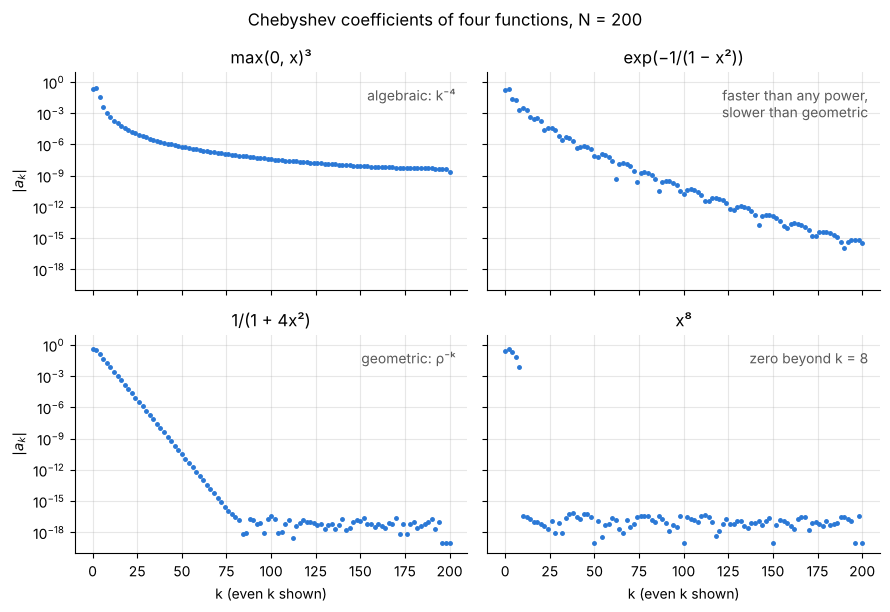

In [7]:
def bump(x):
    inside = np.abs(x) < 1
    safe = np.where(inside, 1 - x**2, 1.0)
    return np.where(inside, np.exp(-1 / safe), 0.0)

tests = {
    "max(0, x)³": lambda x: np.maximum(0, x) ** 3,
    "exp(−1/(1 − x²))": bump,
    "1/(1 + 4x²)": lambda x: 1 / (1 + 4 * x**2),
    "x⁸": lambda x: x**8,
}
notes = ["algebraic: k⁻⁴", "faster than any power,\nslower than geometric", "geometric: ρ⁻ᵏ", "zero beyond k = 8"]

N = 200
x = np.cos(np.pi * np.arange(N + 1) / N)
coefficients = {name: np.abs(cheb_coeffs(f(x))) for name, f in tests.items()}
even = np.arange(0, N + 1, 2)

fig, axes = plt.subplots(2, 2, figsize=(9, 6.2), sharex=True, sharey=True)
for ax, (name, a), note in zip(axes.flat, coefficients.items(), notes):
    ax.semilogy(even, np.maximum(a[even], 1e-19), ".", ms=5)       # exact zeros are drawn at 1e-19
    ax.set(title=name, ylim=(1e-20, 10))
    ax.annotate(note, xy=(0.97, 0.93), xycoords="axes fraction", ha="right", va="top", color="0.35")
for ax in axes[1]:
    ax.set_xlabel("k (even k shown)")
for ax in axes[:, 0]:
    ax.set_ylabel("$|a_k|$")
fig.suptitle("Chebyshev coefficients of four functions, N = 200", y=0.98)
fig.tight_layout()

Only even $k$ are plotted: three of the functions are even, so their odd coefficients vanish,
and the first has no odd coefficients beyond $k = 3$.

**Verify the two rates that theory predicts.** For a function analytic inside the Bernstein
ellipse with parameter $\rho$ (notebook 4), $|a_k|$ decays like $\rho^{-k}$. For
$1/(1+4x^2)$ the poles at $\pm i/2$ give $\rho = (1+\sqrt5)/2$. In the variable $z$ this is
plain: the Laurent series converges in the ring $\rho^{-1} < |z| < \rho$ whose edges pass
through the singularities, and Laurent coefficients decay at the rate set by the ring. When
the derivative of order $p$ has a jump, the coefficients decay like $k^{-(p+1)}$, as for the
Fourier series of notebook 3. The third derivative of $\max(0,x)^3$ jumps, so the rate is $k^{-4}$.

In [8]:
a = coefficients["1/(1 + 4x²)"]
window = even[(even >= 10) & (even <= 60)]
rho_measured = np.exp(-np.polyfit(window, np.log(a[window]), 1)[0])
rho_theory = (1 + np.sqrt(5)) / 2
print(f"1/(1 + 4x²):  measured ρ = {rho_measured:.4f}   theory = {rho_theory:.4f}")
assert abs(rho_measured / rho_theory - 1) < 0.01

a = coefficients["max(0, x)³"]
window = even[(even >= 10) & (even <= 100)]
power = -np.polyfit(np.log(window), np.log(a[window]), 1)[0]
print(f"max(0, x)³:   measured decay k^(-{power:.2f})   theory: k^(-4)")
assert abs(power - 4) < 0.1
assert coefficients["x⁸"][9:].max() < 1e-14 and coefficients["x⁸"][8] > 1e-3

1/(1 + 4x²):  measured ρ = 1.6180   theory = 1.6180
max(0, x)³:   measured decay k^(-4.02)   theory: k^(-4)


The coefficient plot is a fingerprint of the function. A straight line on these axes means
analytic, and its slope tells how far away the nearest singularity is. A curve that flattens
means limited smoothness. A sudden drop to zero means a polynomial.

## 7.4 Is my computation resolved?

In practice the exact answer is unknown and the question is whether $N$ is large enough. The
coefficients answer it.

**Aliasing.** On the grid, a polynomial of degree above $N$ cannot be told apart from one of
lower degree:

$$T_{N+m}(x_j) = \cos\Big(j\pi + \frac{jm\pi}{N}\Big) = (-1)^j\cos\frac{jm\pi}{N} = T_{N-m}(x_j) .$$

So whatever part of the true series lies beyond degree $N$ is folded back about $k = N$ and
added to the computed coefficients just below $N$. If the true coefficients have decayed to
the rounding level by $k = N$, nothing is folded back and the interpolant is as good as the
function. If they have not, the last computed coefficients are visibly large.

In [9]:
N = 16
x = np.cos(np.pi * np.arange(N + 1) / N)
T = lambda k, x: np.cos(k * np.arccos(x))
for m in range(1, N + 1):
    assert np.allclose(T(N + m, x), T(N - m, x), rtol=0, atol=1e-12)
print("T_20 sampled on the N = 16 grid has coefficients:", np.round(cheb_coeffs(T(20, x)), 12).nonzero()[0], "(a single 1 at k = 12)")

T_20 sampled on the N = 16 grid has coefficients: [12] (a single 1 at k = 12)


**A resolution test.** The rule is: a computation is resolved when the coefficients have fallen
to a plateau at the rounding level, about $10^{-16}$ times the largest one. The function `chop`
reports how many terms are needed before everything that follows is below a tolerance. If its
answer is the full length of the series, or within a term or two of it, the function is not
resolved on that grid.

In [10]:
def chop(coeffs, tol=1e-13):
    """Number of leading terms to keep so that every dropped coefficient is below tol times the largest."""
    size = np.abs(np.asarray(coeffs, dtype=float))
    significant = np.nonzero(size > tol * size.max())[0]
    return int(significant[-1]) + 1 if len(significant) else 1

profiles = {"tanh(20x)": lambda x: np.tanh(20 * x), "tanh(2x)": lambda x: np.tanh(2 * x)}
print("terms needed (tolerance 1e-13) as the grid is refined")
print("    N    tanh(20x)       tanh(2x)")
terms = {}
for N in (32, 64, 128, 256, 512, 1024):
    x = np.cos(np.pi * np.arange(N + 1) / N)
    terms[N] = [chop(cheb_coeffs(f(x))) for f in profiles.values()]
    print(f"{N:5d} " + "".join(f"{n if n < N - 1 else 'not resolved':>14}" for n in terms[N]))

terms needed (tolerance 1e-13) as the grid is refined
    N    tanh(20x)       tanh(2x)
   32   not resolved  not resolved
   64   not resolved            42
  128   not resolved            42
  256   not resolved            42
  512            358            42
 1024            358            42


**Verify.** Both functions are analytic, with poles where $\cosh$ vanishes: at
$x = \pm i\pi/(2s)$ for $\tanh(sx)$. The Bernstein parameter is
$\rho = \pi/(2s) + \sqrt{1 + (\pi/(2s))^2}$, and reaching a relative size of $10^{-13}$ takes
about $\ln 10^{13}/\ln\rho$ terms.

tanh(20x): ρ = 1.0816, predicted 382 terms, found 358
tanh(2x): ρ = 2.0570, predicted 42 terms, found 42


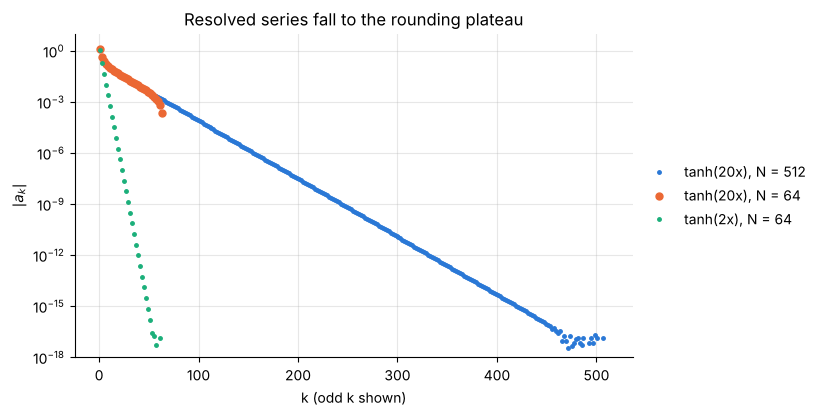

In [11]:
for (name, s), found in zip((("tanh(20x)", 20), ("tanh(2x)", 2)), terms[1024]):
    rho = np.pi / (2 * s) + np.sqrt(1 + (np.pi / (2 * s)) ** 2)
    predicted = np.log(1e13) / np.log(rho)
    print(f"{name}: ρ = {rho:.4f}, predicted {predicted:.0f} terms, found {found}")
    assert abs(found / predicted - 1) < 0.1
assert terms[512] == terms[1024] and terms[256][0] >= 255            # the count stops changing once the grid is fine enough

fig, ax = plt.subplots(figsize=(7.2, 4.2))
for name, N, marker in (("tanh(20x)", 512, "."), ("tanh(20x)", 64, "o"), ("tanh(2x)", 64, ".")):
    x = np.cos(np.pi * np.arange(N + 1) / N)
    a = np.abs(cheb_coeffs(profiles[name](x)))
    odd = np.arange(1, N + 1, 2)                                     # tanh is odd: the even coefficients vanish
    ax.semilogy(odd, a[odd], marker, ms=5, label=f"{name}, N = {N}")
ax.set(xlabel="k (odd k shown)", ylabel="$|a_k|$", ylim=(1e-18, 10), title="Resolved series fall to the rounding plateau")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

With $N = 64$ the coefficients of $\tanh(20x)$ have fallen only to $10^{-3}$ when the grid
runs out: two digits at best, and the plot says so without any reference solution. With
$N = 512$ they pass $10^{-13}$ at $k = 358$ and reach the rounding plateau near $k = 460$;
a finer grid adds nothing. The gentle profile needs 42 terms.

This is a practical way to choose $N$ in any Chebyshev computation: transform the computed
solution and look at the tail. A front of thickness $1/20$ in the **middle** of the interval,
where the Chebyshev grid is coarsest, is the expensive case; the boundary layers of notebook 6
were cheap because they sat where the grid is fine.

## 7.5 Evaluating a series anywhere: Clenshaw's recurrence

**Problem.** Given the coefficients, evaluate $p(x) = \sum_k a_kT_k(x)$ at arbitrary points.

**By hand.** Computing each $T_k(x)$ and summing works but is wasteful. Clenshaw's method is
the counterpart of Horner's rule for a power series. Run the recurrence of the $T_k$ backwards
on the coefficients:

$$b_k = a_k + 2x\,b_{k+1} - b_{k+2},\qquad k = N, N-1, \dots, 1,\qquad b_{N+1} = b_{N+2} = 0 ,$$

and then $p(x) = a_0 + x\,b_1 - b_2$. It costs one multiplication per term and is numerically
stable for $|x| \le 1$.

In [12]:
def clenshaw(coeffs, x):
    """Evaluate the Chebyshev series with the given coefficients at the points x (scalar or array)."""
    x = np.asarray(x, dtype=float)
    b1, b2 = np.zeros_like(x), np.zeros_like(x)
    for a_k in coeffs[:0:-1]:                                        # a_N, a_{N-1}, ..., a_1
        b1, b2 = a_k + 2 * x * b1 - b2, b1
    return coeffs[0] + x * b1 - b2

rng = np.random.default_rng(0)
random_coeffs, points = rng.standard_normal(30), np.linspace(-1, 1, 101)
assert np.allclose(clenshaw(random_coeffs, points), np.polynomial.chebyshev.chebval(points, random_coeffs), rtol=0, atol=1e-12)
x = np.cos(np.pi * np.arange(9) / 8)
assert abs(clenshaw(cheb_coeffs(np.exp(x)), 0.3) - np.exp(0.3)) < 5e-8             # nine samples of exp, evaluated off the grid

## 7.6 Worked example: a rate constant as a short series

**Problem.** A reactor simulation evaluates the Arrhenius rate constant

$$k(T) = A\exp\!\Big(-\frac{E}{RT}\Big),\qquad A = 10^{10}\ \text{s}^{-1},\quad E/R = 8000\ \text{K},$$

millions of times for temperatures between 300 K and 600 K. Replace it by a Chebyshev series
with a relative error below $10^{-8}$ over the whole range. How many terms are needed? The
Arrhenius law is cheap to evaluate, so here it stands in for something that is not: a property
from a table, an equilibrium calculation, a correlation with many branches. The procedure is
the same. (In this section $k$ is the rate constant and $T$ the temperature, not a series
index and a Chebyshev polynomial.)

**By hand.** Map the range to $[-1, 1]$ with $T = 450 + 150x$. Sample the function at the
Chebyshev points, transform to coefficients, keep the leading terms and evaluate with
`clenshaw`. There is one decision to make first. Over this range $k$ grows by a factor of
$e^{8000/300 - 8000/600} \approx 6\times10^5$, so a relative error of $10^{-8}$ at the cold
end is an absolute error of about $10^{-14}$ of the value at the hot end. A function that
spans many decades is better approximated through its **logarithm**:
$\ln k = \ln A - (E/R)/T$ is a gentle function, and an absolute error of $10^{-8}$ in $\ln k$
is a relative error of $10^{-8}$ in $k$ at every temperature. We try both.

chop, from the coefficients of ln k alone, suggests keeping 13 terms
terms needed for a relative error below 1e-8:  series for ln k: 13   series for k: 20


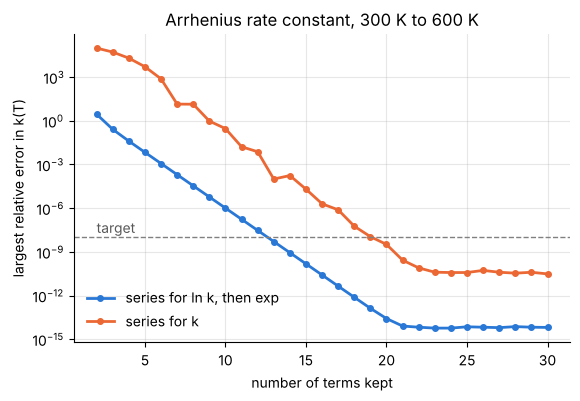

In [13]:
A_pre, E_over_R = 1e10, 8000.0
T_low, T_high = 300.0, 600.0
to_T = lambda x: (T_high + T_low) / 2 + (T_high - T_low) / 2 * x
to_x = lambda T: (2 * T - T_high - T_low) / (T_high - T_low)
rate = lambda T: A_pre * np.exp(-E_over_R / T)

N = 48
x = np.cos(np.pi * np.arange(N + 1) / N)
coeffs_log = cheb_coeffs(np.log(rate(to_T(x))))                     # series for ln k
coeffs_direct = cheb_coeffs(rate(to_T(x)))                          # series for k itself
n_chop = chop(coeffs_log, tol=1e-8 / np.abs(coeffs_log).max())    # terms of ln k above 1e-8 in absolute size
print(f"chop, from the coefficients of ln k alone, suggests keeping {n_chop} terms")

T_test = np.linspace(T_low, T_high, 3001)
terms_tried = np.arange(2, 31)
error_log = [np.abs(np.exp(clenshaw(coeffs_log[:n], to_x(T_test))) / rate(T_test) - 1).max() for n in terms_tried]
error_direct = [np.abs(clenshaw(coeffs_direct[:n], to_x(T_test)) / rate(T_test) - 1).max() for n in terms_tried]
n_log = int(terms_tried[np.argmax(np.array(error_log) < 1e-8)])
n_direct = int(terms_tried[np.argmax(np.array(error_direct) < 1e-8)])
print(f"terms needed for a relative error below 1e-8:  series for ln k: {n_log}   series for k: {n_direct}")

fig, ax = plt.subplots()
ax.semilogy(terms_tried, error_log, "o-", ms=4, label="series for ln k, then exp")
ax.semilogy(terms_tried, error_direct, "o-", ms=4, label="series for k")
ax.axhline(1e-8, color="0.5", lw=1, ls="--")
ax.annotate("target", xy=(2, 2e-8), color="0.35")
ax.set(xlabel="number of terms kept", ylabel="largest relative error in k(T)", title="Arrhenius rate constant, 300 K to 600 K")
ax.legend(frameon=False, loc="lower left");

**Verify** the accuracy of the short series on the fine grid of 3001 temperatures, and the
decay rate. As a function of $x$, $1/T$ has a pole at $T = 0$, which is $x = -3$. The
Bernstein ellipse through $x = -3$ has $\rho = 3 + \sqrt{8} \approx 5.83$: every extra term
buys a factor of nearly six.

In [14]:
rate_series = lambda T: np.exp(clenshaw(coeffs_log[:n_log], to_x(T)))
worst = np.abs(rate_series(T_test) / rate(T_test) - 1).max()
print(f"{n_log}-term series for ln k: largest relative error {worst:.1e}")
assert worst < 1e-8 and n_log <= 14 and n_log < n_direct and abs(n_chop - n_log) <= 1

ks = np.arange(2, 14)
rho_measured = np.exp(-np.polyfit(ks, np.log(np.abs(coeffs_log[ks])), 1)[0])
print(f"decay of the coefficients of ln k: ρ = {rho_measured:.3f}   theory 3 + √8 = {3 + np.sqrt(8):.3f}")
assert abs(rho_measured / (3 + np.sqrt(8)) - 1) < 0.01

13-term series for ln k: largest relative error 5.1e-09
decay of the coefficients of ln k: ρ = 5.828   theory 3 + √8 = 5.828


Thirteen numbers reproduce the rate constant to eight digits everywhere between 300 K and
600 K, and `chop` predicted that count from the coefficients alone, with no test grid. The
direct series needs about half as many terms again, and its error curve stalls
near $10^{-10}$, because rounding errors of relative size $10^{-16}$ at the hot end are
$10^{-10}$ of the value at the cold end. The lesson is general: when a quantity varies over
decades (rate constants, vapour pressures, viscosities), approximate its logarithm. And look at
the coefficients before choosing the length of the series. They show what each term buys.

## 7.7 Differentiating in coefficient space

**Problem.** Given the coefficients $a_k$ of $p$, find the coefficients $b_k$ of $p'$ without
forming the differentiation matrix.

**By hand.** Differentiate $T_k = \cos k\theta$ with the chain rule: $T_k' = k\sin k\theta/\sin\theta$.
From $\sin(k+1)\theta - \sin(k-1)\theta = 2\sin\theta\cos k\theta$ it follows that

$$\frac{T_{k+1}'}{k+1} - \frac{T_{k-1}'}{k-1} = 2T_k\qquad (k \ge 2),$$

together with $T_1' = T_0$ and $T_2' = 4T_1$. Integrate $p' = \sum b_kT_k$ term by term with
these identities and compare with $p = \sum a_kT_k$. The coefficient of $T_k$ gives
$2k\,a_k = \gamma_{k-1}b_{k-1} - b_{k+1}$ with $\gamma_0 = 2$ and $\gamma_k = 1$ otherwise, or

$$b_{k-1} = b_{k+1} + 2k\,a_k\quad (k = N, N-1, \dots, 2),\qquad b_0 = \tfrac12 b_2 + a_1 ,$$

started from $b_N = b_{N+1} = 0$, since $p'$ has degree $N-1$. The work is $O(N)$. With a
transform before and after, the derivative at the grid points costs $O(N\log N)$, where the
matrix product costs $O(N^2)$.

In [15]:
def cheb_coeff_derivative(a):
    """Coefficients of p'(x) from the coefficients of p(x), by the backward recurrence."""
    a = np.asarray(a, dtype=float)
    N = len(a) - 1
    b = np.zeros(N + 1)
    if N == 0:
        return b
    b[N - 1] = 2 * N * a[N]
    for k in range(N - 2, -1, -1):
        b[k] = b[k + 2] + 2 * (k + 1) * a[k + 1]
    b[0] /= 2
    return b

def cheb_derivative_fft(values):
    """Derivative at the Chebyshev points in O(N log N): transform, differentiate, transform back."""
    return cheb_values(cheb_coeff_derivative(cheb_coeffs(values)))

**Verify** on a known case, $T_3' = 12x^2 - 3 = 3T_0 + 6T_2$, and against the matrix of
notebook 5, which must give the same derivative of the same polynomial up to rounding.

In [16]:
assert np.allclose(cheb_coeff_derivative([0, 0, 0, 1.0]), [3, 0, 6, 0], rtol=0, atol=1e-14)
N = 32
D, x = cheb(N)
v = np.exp(x) * np.sin(3 * x)
difference = np.abs(cheb_derivative_fft(v) - D @ v).max()
print(f"N = {N}: largest difference between the transform and the matrix derivative: {difference:.1e}")
assert difference < 1e-11
assert np.abs(cheb_derivative_fft(v) - np.exp(x) * (np.sin(3 * x) + 3 * np.cos(3 * x))).max() < 1e-11

N = 32: largest difference between the transform and the matrix derivative: 2.1e-13


In [17]:
# best_time(function, repeats) from notebook 2
def best_time(function, repeats=25):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        times.append(time.perf_counter() - start)
    return min(times)

print("     N    build D (ms)    D @ v (ms)    transforms (ms)    memory for D (MB)")
for N in (64, 256, 1024, 4096):
    build = best_time(lambda: cheb(N), repeats=2)
    D, x = cheb(N)
    v = np.exp(x) * np.sin(3 * x)
    print(f"{N:6d} {1e3 * build:13.2f} {1e3 * best_time(lambda: D @ v, repeats=5):13.3f} {1e3 * best_time(lambda: cheb_derivative_fft(v), repeats=5):16.3f}"
          f" {D.nbytes / 1e6:17.1f}")
del D

     N    build D (ms)    D @ v (ms)    transforms (ms)    memory for D (MB)
    64          0.66         0.004            0.099               0.0
   256          0.88         0.021            0.276               0.5
  1024         21.24         0.185            1.116               8.4


  4096        233.08         4.777            1.537             134.3


The timings depend on the machine, but the pattern does not. For small $N$ the matrix product
is faster: it is a single optimized library call, and the recurrence above is a Python loop.
Once $N$ is large, each fourfold increase of $N$ multiplies the memory for the matrix by
sixteen and the time to build or apply it by ten or more, while the cost of the transform
route grows far more slowly. In one
dimension with a few dozen points the matrix is the right tool, and it has the advantage that
boundary value problems can be solved with it directly (notebook 6). The transform is the right
tool when $N$ is in the thousands, and for time-stepping problems on large grids where only
derivatives of known data are needed.

## Summary

- $T_k(\cos\theta) = \cos k\theta$: a Chebyshev series is a Fourier cosine series in $\theta$
  and a Laurent series in $z = e^{i\theta}$. The Chebyshev points are equally spaced in $\theta$.
- `cheb_coeffs` and `cheb_values` move between values and coefficients with a discrete cosine
  transform, in $O(N\log N)$ operations.
- The decay of the coefficients shows the smoothness of the function, and their tail shows
  whether the grid resolves it. Check the tail before trusting a spectral computation.
- On the grid, degree $N + m$ is aliased to degree $N - m$.
- `clenshaw` evaluates a series anywhere. A smooth function can be replaced by a short series,
  and quantities that span decades should be approximated through their logarithm.
- Differentiation is a two-term recurrence on the coefficients.

## Exercises

1. Use $x = \tfrac12(z + z^{-1})$ to expand $x^4$ in Chebyshev polynomials by hand, and check
   your answer with `cheb_coeffs` on a grid with $N = 6$.
2. For $f(x) = 1/(1 + 25x^2)$ predict the decay rate $\rho$ of the Chebyshev coefficients from
   the position of the poles. Measure it from the coefficients on a grid with $N = 300$, and
   use `chop` to find the number of terms needed for a tolerance of $10^{-10}$.
3. A boundary layer of thickness $\varepsilon$ at $x = -1$ is modelled by
   $u(x) = \exp\!\big(-(1+x)/\varepsilon\big)$. Using a grid with $N = 2048$ and `chop` with
   tolerance $10^{-10}$, find the number of terms needed for $\varepsilon = 10^{-1}, 10^{-2},
   10^{-3}$ and $10^{-4}$. How does the number scale with $\varepsilon$? Compare with the number
   of equally spaced points needed to put ten points inside the layer.
4. Running the identity of 7.7 the other way gives the coefficients of an antiderivative
   $P(x) = \int p\,dx$: $A_k = (\gamma_{k-1}a_{k-1} - a_{k+1})/(2k)$ for $k \ge 1$, with
   $\gamma_0 = 2$, $\gamma_k = 1$ otherwise and $a_{N+1} = a_{N+2} = 0$. Write
   `cheb_coeff_integral(a)`, choosing $A_0$ so that $P(-1) = 0$, and check that
   `cheb_coeff_derivative` undoes it. Use it with `clenshaw` to compute
   $\int_{-1}^{1} e^{x}\sin 3x\,dx$ with $N = 24$ and compare with the exact value.
5. The Colebrook equation for the Darcy friction factor of turbulent pipe flow,
   $1/\sqrt f = -2\log_{10}\!\big(\tfrac{\epsilon/D}{3.7} + \tfrac{2.51}{Re\sqrt f}\big)$, has to
   be solved iteratively. For relative roughness $\epsilon/D = 10^{-4}$, sample $f$ at
   Chebyshev points in the variable $\log_{10}Re$ over $4\times10^3 \le Re \le 10^8$ (solve
   the equation at each point with `scipy.optimize.brentq`), using $N = 64$. How many terms
   of the series give a relative error below $10^{-6}$ on a fine grid of 2000 Reynolds
   numbers? Evaluate the series with `clenshaw`.